A Census API key is required to retrieve the ACS data.
Request a free key at: https://api.census.gov/data/key_signup.html
Enter your Census API key: ··········
Requesting Maryland population data from the Census API...
Retrieved 24 Maryland county records.
Loaded 24 Maryland county boundaries.
ACS data successfully joined to county boundaries.
Original coordinate reference system: EPSG:4269
Map projection: EPSG:26918

Population density preview:
        NAME  Population  Land_Area_SqMi  Population_Density
0  Worcester       53700      468.298419          114.670470
1   Allegany       67452      422.198805          159.763598
2  Baltimore      573243       80.946058         7081.790190
3      Cecil      104960      346.299868          303.089922
4  Baltimore      850796      598.358210         1421.884059
Map exported successfully: /content/maryland_population_density_scalebar.png


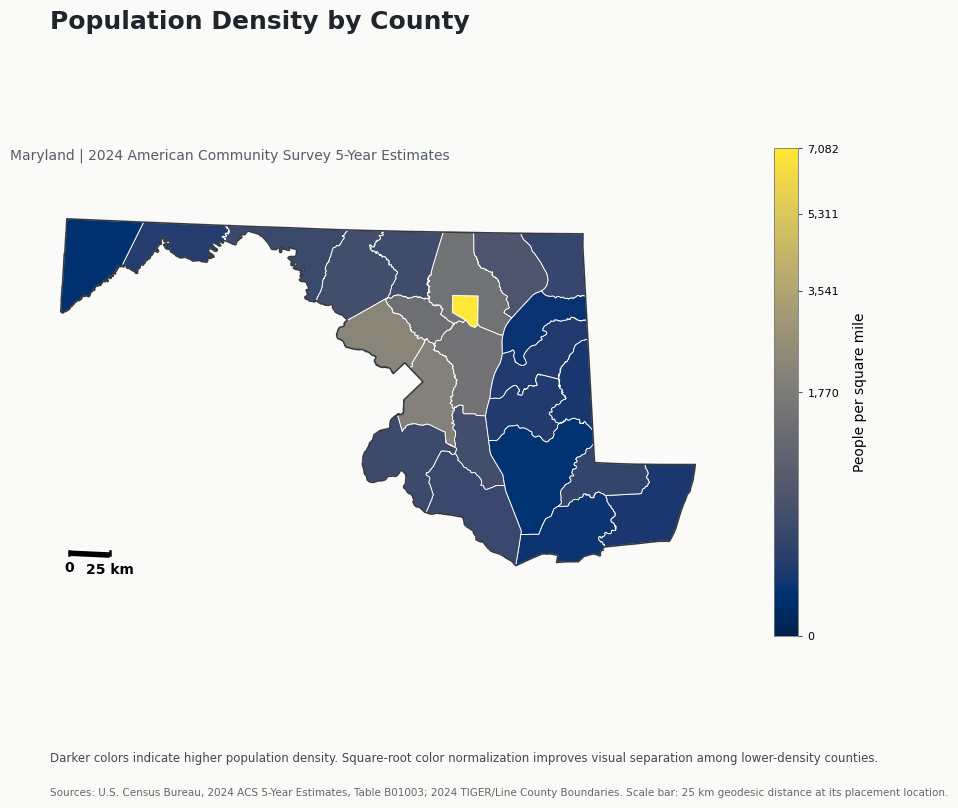

In [4]:
"""
Maryland County Population Density Map with a Geodesic Scale Bar
================================================================

Data sources
------------
1. U.S. Census Bureau, 2024 ACS 5-Year Estimates, Table B01003
   - B01003_001E: Total population estimate
   - B01003_001M: Total population margin of error
2. U.S. Census Bureau, 2024 TIGER/Line County boundaries
   - ALAND: Land area in square meters
   - GEOID: Five-character county geographic identifier

What this script does
---------------------
- Retrieves Maryland county population estimates from the Census API.
- Downloads 2024 TIGER/Line county boundaries.
- Joins the ACS estimates to county boundaries using GEOID.
- Calculates population density per square mile.
- Projects the counties to NAD83 / UTM Zone 18N (EPSG:26918).
- Draws a color-vision-deficiency-friendly choropleth and a 25-kilometer geodesic scale bar.
- Saves the map as maryland_population_density_scalebar.png.

Before running
-------------
Install packages:
    pip install requests pandas geopandas matplotlib pyproj

When the script runs, it prompts you to enter your Census API key.
The key is entered using getpass, so it is not displayed as you type.
You can also set CENSUS_API_KEY as an environment variable if preferred.

Get a Census API key:
    https://api.census.gov/data/key_signup.html

Then run:
    python scalebar_example.py
"""

import os
import tempfile
from getpass import getpass
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm
from matplotlib.cm import ScalarMappable
import pandas as pd
import requests
from matplotlib import patheffects
from pyproj import Geod, Transformer


# ---------------------------------------------------------------------
# 1. CONFIGURATION
# ---------------------------------------------------------------------

ACS_YEAR = 2024
STATE_FIPS = "24"  # Maryland
TARGET_CRS = "EPSG:26918"  # NAD83 / UTM Zone 18N
SCALE_DISTANCE_METERS = 25_000  # 25 kilometers

OUTPUT_FILE = Path("maryland_population_density_scalebar.png")

# Use an environment variable if one is already set; otherwise prompt.
# getpass hides the key as it is typed so it is not echoed in the terminal.
CENSUS_API_KEY = os.getenv("CENSUS_API_KEY")

if not CENSUS_API_KEY:
    print("A Census API key is required to retrieve the ACS data.")
    print("Request a free key at: https://api.census.gov/data/key_signup.html")
    CENSUS_API_KEY = getpass("Enter your Census API key: ").strip()

if not CENSUS_API_KEY:
    raise ValueError("No Census API key was entered. The script cannot continue.")

CENSUS_API_URL = (
    f"https://api.census.gov/data/{ACS_YEAR}/acs/acs5"
)

TIGER_COUNTY_URL = (
    "https://www2.census.gov/geo/tiger/"
    "TIGER2024/COUNTY/tl_2024_us_county.zip"
)


# ---------------------------------------------------------------------
# 2. RETRIEVE ACS POPULATION DATA
# ---------------------------------------------------------------------

def get_acs_population_data() -> pd.DataFrame:
    """Retrieve county-level total population and margin of error."""

    params = {
        "get": "NAME,B01003_001E,B01003_001M",
        "for": "county:*",
        "in": f"state:{STATE_FIPS}",
        "key": CENSUS_API_KEY,
    }

    print("Requesting Maryland population data from the Census API...")

    response = requests.get(
        CENSUS_API_URL,
        params=params,
        timeout=60,
    )
    response.raise_for_status()

    rows = response.json()
    if len(rows) < 2:
        raise ValueError("The Census API returned no county records.")

    # The first API row contains column names; remaining rows contain data.
    population_df = pd.DataFrame(rows[1:], columns=rows[0])

    # Convert Census estimate and margin-of-error fields to numeric values.
    population_df["B01003_001E"] = pd.to_numeric(
        population_df["B01003_001E"], errors="coerce"
    )
    population_df["B01003_001M"] = pd.to_numeric(
        population_df["B01003_001M"], errors="coerce"
    )

    # County GEOID = 2-digit state FIPS + 3-digit county FIPS.
    population_df["GEOID"] = (
        population_df["state"].astype(str).str.zfill(2)
        + population_df["county"].astype(str).str.zfill(3)
    )

    population_df = population_df.rename(
        columns={
            "NAME": "County",
            "B01003_001E": "Population",
            "B01003_001M": "Population_MOE",
        }
    )

    population_df = population_df[
        ["GEOID", "County", "Population", "Population_MOE"]
    ]

    print(f"Retrieved {len(population_df)} Maryland county records.")
    return population_df


# ---------------------------------------------------------------------
# 3. DOWNLOAD AND LOAD TIGER/LINE COUNTY BOUNDARIES
# ---------------------------------------------------------------------

def get_maryland_counties() -> gpd.GeoDataFrame:
    """Download the 2024 TIGER/Line county file and select Maryland."""

    print("Downloading 2024 TIGER/Line county boundaries...")

    # Download to a temporary ZIP file so GeoPandas can read it reliably.
    temporary_zip = None

    try:
        with tempfile.NamedTemporaryFile(
            suffix=".zip", delete=False
        ) as temp_file:
            temporary_zip = Path(temp_file.name)

        response = requests.get(
            TIGER_COUNTY_URL,
            timeout=120,
        )
        response.raise_for_status()
        temporary_zip.write_bytes(response.content)

        counties = gpd.read_file(temporary_zip)

    finally:
        if temporary_zip is not None and temporary_zip.exists():
            temporary_zip.unlink()

    if counties.crs is None:
        raise ValueError(
            "The TIGER/Line boundary file does not have a defined CRS."
        )

    # STATEFP is the two-digit state FIPS code.
    maryland = counties.loc[
        counties["STATEFP"].astype(str).str.zfill(2) == STATE_FIPS
    ].copy()

    if maryland.empty:
        raise ValueError("No Maryland counties were found in the TIGER file.")

    maryland["GEOID"] = maryland["GEOID"].astype(str).str.zfill(5)

    print(f"Loaded {len(maryland)} Maryland county boundaries.")
    return maryland


# ---------------------------------------------------------------------
# 4. JOIN ACS DATA TO GEOGRAPHIC BOUNDARIES
# ---------------------------------------------------------------------

def join_population_to_boundaries(
    maryland: gpd.GeoDataFrame,
    population_df: pd.DataFrame,
) -> gpd.GeoDataFrame:
    """Join ACS estimates to TIGER/Line county polygons using GEOID."""

    maryland = maryland.merge(
        population_df,
        on="GEOID",
        how="left",
        validate="one_to_one",
    )

    if maryland["Population"].isna().any():
        unmatched = maryland.loc[
            maryland["Population"].isna(), "GEOID"
        ].tolist()
        raise ValueError(
            f"ACS population data did not match these county GEOIDs: {unmatched}"
        )

    # TIGER/Line ALAND is land area in square meters.
    # 1 square mile = 2,589,988.110336 square meters.
    square_meters_per_square_mile = 2_589_988.110336

    maryland["Land_Area_SqMi"] = (
        maryland["ALAND"] / square_meters_per_square_mile
    )

    # Avoid division by zero if a geometry has no reported land area.
    maryland = maryland.loc[
        maryland["Land_Area_SqMi"] > 0
    ].copy()

    # Population density is more appropriate than raw population
    # for comparing counties with different land areas.
    maryland["Population_Density"] = (
        maryland["Population"] / maryland["Land_Area_SqMi"]
    )

    print("ACS data successfully joined to county boundaries.")
    return maryland


# ---------------------------------------------------------------------
# 5. PROJECT THE MAP
# ---------------------------------------------------------------------

def project_map(
    maryland: gpd.GeoDataFrame,
) -> gpd.GeoDataFrame:
    """Project county geometries into NAD83 / UTM Zone 18N."""

    print("Original coordinate reference system:", maryland.crs)

    projected = maryland.to_crs(TARGET_CRS)

    print("Map projection:", projected.crs)
    return projected


# ---------------------------------------------------------------------
# 6. DRAW A GEODESIC SCALE BAR
# ---------------------------------------------------------------------

def add_geodesic_scale_bar(
    ax,
    map_gdf: gpd.GeoDataFrame,
    distance_meters: float,
) -> None:
    """
    Add a scale bar representing a specified geodesic distance.

    The bar's endpoints are calculated using the GRS80 ellipsoid,
    which is consistent with the NAD83 datum used by the target CRS.
    The distance is accurate at the scale bar's placement location.
    """

    # Transform between the projected map CRS and geographic coordinates.
    to_geographic = Transformer.from_crs(
        TARGET_CRS,
        "EPSG:4269",  # NAD83 geographic coordinates
        always_xy=True,
    )

    to_projected = Transformer.from_crs(
        "EPSG:4269",
        TARGET_CRS,
        always_xy=True,
    )

    geod = Geod(ellps="GRS80")

    # Place the scale bar near the lower-left corner of the map.
    # Axes coordinates are relative to the plotting area (0 to 1).
    anchor_axes_x = 0.08
    anchor_axes_y = 0.10

    # Convert the axes-relative anchor point into map data coordinates.
    anchor_x, anchor_y = ax.transData.inverted().transform(
        ax.transAxes.transform((anchor_axes_x, anchor_axes_y))
    )

    # Convert the anchor point to longitude/latitude.
    start_lon, start_lat = to_geographic.transform(
        anchor_x,
        anchor_y,
    )

    # Calculate a point exactly 25 km east along the GRS80 ellipsoid.
    end_lon, end_lat, _ = geod.fwd(
        start_lon,
        start_lat,
        90,  # azimuth: due east
        distance_meters,
    )

    # Transform the geodesic endpoints back to the projected map CRS.
    start_x, start_y = to_projected.transform(
        start_lon,
        start_lat,
    )
    end_x, end_y = to_projected.transform(
        end_lon,
        end_lat,
    )

    # Use map height to size the end ticks proportionally.
    map_height = (
        map_gdf.total_bounds[3] - map_gdf.total_bounds[1]
    )
    tick_height = map_height * 0.012

    # Draw the scale bar line with a white outline for contrast.
    scale_line, = ax.plot(
        [start_x, end_x],
        [start_y, end_y],
        color="black",
        linewidth=4,
        solid_capstyle="butt",
        zorder=10,
    )
    scale_line.set_path_effects(
        [
            patheffects.Stroke(linewidth=6, foreground="white"),
            patheffects.Normal(),
        ]
    )

    # Draw vertical ticks at both ends of the scale bar.
    for x in (start_x, end_x):
        ax.plot(
            [x, x],
            [
                start_y - tick_height / 2,
                start_y + tick_height / 2,
            ],
            color="black",
            linewidth=1.8,
            zorder=11,
        )

    # Add labels beneath the scale bar.
    label_offset = tick_height * 1.8

    ax.text(
        start_x,
        start_y - label_offset,
        "0",
        ha="center",
        va="top",
        fontsize=10,
        fontweight="bold",
        zorder=12,
    )

    distance_label = (
        f"{distance_meters / 1000:g} km"
        if distance_meters >= 1000
        else f"{distance_meters:g} m"
    )

    ax.text(
        end_x,
        end_y - label_offset,
        distance_label,
        ha="center",
        va="top",
        fontsize=10,
        fontweight="bold",
        zorder=12,
    )


# ---------------------------------------------------------------------
# 7. CREATE THE CHOROPLETH MAP
# ---------------------------------------------------------------------

def create_map(maryland: gpd.GeoDataFrame) -> None:
    """Plot an accessible population-density choropleth and scale bar."""

    # Cividis is a perceptually uniform sequential palette designed to
    # remain interpretable for viewers with common forms of color-vision
    # deficiency and when the map is reproduced in grayscale.
    cmap = plt.get_cmap("cividis")

    # Population density is often right-skewed. A square-root
    # normalization makes variation among less-dense counties easier
    # to distinguish without changing the underlying data values.
    vmax = float(maryland["Population_Density"].max())
    if vmax <= 0:
        raise ValueError("Population density values must be greater than zero.")

    norm = PowerNorm(
        gamma=0.5,
        vmin=0,
        vmax=vmax,
    )

    fig, ax = plt.subplots(figsize=(10, 8.5), facecolor="#FAFAF8")
    ax.set_facecolor("#FAFAF8")

    # Draw counties with subtle boundaries so the thematic colors remain
    # the primary focus of the map.
    maryland.plot(
        column="Population_Density",
        cmap=cmap,
        norm=norm,
        linewidth=0.65,
        edgecolor="#FFFFFF",
        ax=ax,
        zorder=2,
    )

    # Add a slightly stronger outline around the overall state footprint.
    maryland.dissolve().boundary.plot(
        ax=ax,
        color="#343A40",
        linewidth=1.15,
        zorder=3,
    )

    # Build a continuous colorbar with labels expressed in the original
    # population-density units (people per square mile).
    colorbar_mappable = ScalarMappable(norm=norm, cmap=cmap)
    colorbar_mappable.set_array([])

    colorbar = fig.colorbar(
        colorbar_mappable,
        ax=ax,
        orientation="vertical",
        fraction=0.045,
        pad=0.035,
        shrink=0.82,
    )
    colorbar.set_label(
        "People per square mile",
        fontsize=10,
        labelpad=10,
    )

    # Use evenly spaced values in the original data units for colorbar ticks.
    tick_values = [vmax * i / 4 for i in range(5)]
    colorbar.set_ticks(tick_values)
    colorbar.set_ticklabels([f"{value:,.0f}" for value in tick_values])
    colorbar.ax.tick_params(labelsize=8, length=3, color="#555555")
    colorbar.outline.set_linewidth(0.6)
    colorbar.outline.set_edgecolor("#777777")

    # Title and subtitle establish the subject, geography, and data vintage.
    fig.suptitle(
        "Population Density by County",
        x=0.12,
        y=0.96,
        ha="left",
        fontsize=18,
        fontweight="bold",
        color="#20252B",
    )
    ax.set_title(
        "Maryland | 2024 American Community Survey 5-Year Estimates",
        loc="left",
        fontsize=10,
        color="#555D66",
        pad=12,
    )

    ax.set_axis_off()

    # Set map limits and add modest whitespace around the state.
    minx, miny, maxx, maxy = maryland.total_bounds
    x_padding = (maxx - minx) * 0.08
    y_padding = (maxy - miny) * 0.08

    ax.set_xlim(minx - x_padding, maxx + x_padding)
    ax.set_ylim(miny - y_padding, maxy + y_padding)
    ax.set_aspect("equal")

    # Add a 25 km geodesic scale bar after the map extent is established.
    add_geodesic_scale_bar(
        ax=ax,
        map_gdf=maryland,
        distance_meters=SCALE_DISTANCE_METERS,
    )

    # Explain the visual encoding and document the sources.
    fig.text(
        0.12,
        0.075,
        (
            "Darker colors indicate higher population density. "
            "Square-root color normalization improves visual separation "
            "among lower-density counties."
        ),
        ha="left",
        fontsize=8.5,
        color="#42484F",
    )
    fig.text(
        0.12,
        0.035,
        (
            "Sources: U.S. Census Bureau, 2024 ACS 5-Year Estimates, "
            "Table B01003; 2024 TIGER/Line County Boundaries. "
            "Scale bar: 25 km geodesic distance at its placement location."
        ),
        ha="left",
        fontsize=7.5,
        color="#666666",
    )

    # Reserve space for the title and source notes.
    fig.subplots_adjust(
        left=0.08,
        right=0.88,
        top=0.86,
        bottom=0.16,
    )

    # Export at print-quality resolution.
    plt.savefig(
        OUTPUT_FILE,
        dpi=300,
        bbox_inches="tight",
        facecolor=fig.get_facecolor(),
    )

    print(f"Map exported successfully: {OUTPUT_FILE.resolve()}")
    plt.show()


# ---------------------------------------------------------------------
# 8. RUN THE WORKFLOW
# ---------------------------------------------------------------------

def main() -> None:
    """Run the complete Census data-to-map workflow."""

    population_df = get_acs_population_data()
    maryland_counties = get_maryland_counties()

    maryland = join_population_to_boundaries(
        maryland=maryland_counties,
        population_df=population_df,
    )

    maryland = project_map(maryland)

    # Print a quick data check before generating the map.
    print("\nPopulation density preview:")
    print(
        maryland[
            ["NAME", "Population", "Land_Area_SqMi", "Population_Density"]
        ].head()
    )

    create_map(maryland)


if __name__ == "__main__":
    main()
